# LexLitIA | Actividad 4
## Comparacion de modelos preentrenados

**Materia:** Gestion de Proyectos de Inteligencia Artificial

**Caso de uso:** Clasificacion inicial de reclamaciones
juridico-bancarias en Mexico.

**Categorias:** Tarjeta de Debito, Tarjeta de Credito,
Cheques, Canales Digitales y Otros.

**Modelos:** mDeBERTa, XLM-RoBERTa y BART.

**Metodo:** Clasificacion zero-shot con GPU T4.

**Dataset:** 50 extractos sinteticos;
25 de desarrollo y 25 de evaluacion.

**Alcance:** Experimento academico, no apto
para clasificacion juridica autonoma.

**Instruccion:** Ejecutar las etapas en orden.
Los resultados pueden variar ligeramente entre
sesiones y versiones de software.


## ETAPA 1. Definicion del caso de uso

**Fase:** Planteamiento juridico y funcional

**Objetivo:** Documentar las categorias y reglas de clasificacion.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

In [1]:
CATEGORIAS = [
    "Tarjeta de Debito",
    "Tarjeta de Credito",
    "Cheques",
    "Canales Digitales",
    "Otros"
]

REGLAS = {
    "Tarjeta de Debito":
        "Tarjeta de debito, incluyendo pagos fisicos "
        "o contactless en TPV.",
    "Tarjeta de Credito":
        "Tarjeta de credito, cargos, intereses, "
        "saldos y pagos fisicos o contactless.",
    "Cheques":
        "Emision, presentacion, cobro, pago, "
        "devolucion o alteracion de cheques.",
    "Canales Digitales":
        "Transferencias y operaciones por banca "
        "movil o internet, excluyendo pagos "
        "con tarjeta en TPV.",
    "Otros":
        "Productos o servicios bancarios no "
        "comprendidos en las categorias anteriores."
}

print("LEXLITIA | DEFINICION FUNCIONAL")
for categoria, regla in REGLAS.items():
    print("\n", categoria, ":", regla)

print("\nConclusion: cinco categorias excluyentes.")

LEXLITIA | DEFINICION FUNCIONAL

 Tarjeta de Debito : Tarjeta de debito, incluyendo pagos fisicos o contactless en TPV.

 Tarjeta de Credito : Tarjeta de credito, cargos, intereses, saldos y pagos fisicos o contactless.

 Cheques : Emision, presentacion, cobro, pago, devolucion o alteracion de cheques.

 Canales Digitales : Transferencias y operaciones por banca movil o internet, excluyendo pagos con tarjeta en TPV.

 Otros : Productos o servicios bancarios no comprendidos en las categorias anteriores.

Conclusion: cinco categorias excluyentes.


## ETAPA 2. Configuracion del entorno

**Fase:** Preparacion tecnica

**Objetivo:** Instalar dependencias y verificar GPU y versiones.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

In [2]:
import sys
import subprocess

paquetes = [
    "transformers==4.57.6",
    "datasets==4.8.5",
    "huggingface-hub==0.36.2",
    "accelerate==1.15.0",
    "scikit-learn==1.6.1",
    "pandas==2.2.3",
    "matplotlib==3.10.0",
    "sentencepiece==0.2.2",
    "safetensors==0.8.0"
]

subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "-q", *paquetes],
    check=True
)

import torch
import transformers
import pandas as pd
import sklearn
from pathlib import Path

assert torch.cuda.is_available(), (
    "Activa GPU T4 en Entorno de ejecucion."
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA disponible:", torch.cuda.is_available())

RAIZ = Path("/content/LexLitIA_Actividad4")
DATOS = RAIZ / "data"
RESULTADOS = RAIZ / "results"
FIGURAS = RESULTADOS / "figuras"

for ruta in [DATOS, RESULTADOS, FIGURAS]:
    ruta.mkdir(parents=True, exist_ok=True)

print("Conclusion: entorno preparado.")

Python: 3.13.15
PyTorch: 2.11.0+cu130
Transformers: 4.57.6
GPU: Tesla T4
CUDA disponible: True
Conclusion: entorno preparado.


## ETAPA 3. Carga y validacion del dataset

**Fase:** Gestion de datos

**Objetivo:** Cargar los CSV y comprobar etiquetas y particiones.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

In [3]:
import pandas as pd
from pathlib import Path

archivo = DATOS / "lexlitia_dataset.csv"

if not archivo.exists():
    from google.colab import files
    print("Carga lexlitia_dataset.csv")
    subidos = files.upload()

    if "lexlitia_dataset.csv" not in subidos:
        raise FileNotFoundError(
            "Debes seleccionar lexlitia_dataset.csv"
        )

    archivo.write_bytes(
        subidos["lexlitia_dataset.csv"]
    )

df = pd.read_csv(archivo, encoding="utf-8-sig")

columnas = [
    "familia_id", "categoria_real",
    "particion", "texto_demanda"
]

assert set(columnas).issubset(df.columns)
assert len(df) == 50
assert df["familia_id"].is_unique
assert df["texto_demanda"].notna().all()
assert set(df["categoria_real"]) == set(CATEGORIAS)

desarrollo = df[df.particion == "Desarrollo"].copy()
evaluacion = df[df.particion == "Evaluacion"].copy()

assert len(desarrollo) == 25
assert len(evaluacion) == 25

assert evaluacion["categoria_real"].value_counts().eq(5).all()
assert not set(desarrollo.familia_id) & set(evaluacion.familia_id)
assert not set(desarrollo.texto_demanda) & set(evaluacion.texto_demanda)

print("LEXLITIA | DATASET VALIDADO")
display(pd.crosstab(
    df.categoria_real, df.particion
))

print("Total:", len(df))
print("Evaluacion:", len(evaluacion))
print("Conclusion: datos preparados para inferencia.")

Carga lexlitia_dataset.csv


Saving lexlitia_dataset.csv to lexlitia_dataset.csv
LEXLITIA | DATASET VALIDADO


particion,Desarrollo,Evaluacion
categoria_real,,
Canales Digitales,5,5
Cheques,5,5
Otros,5,5
Tarjeta de Credito,5,5
Tarjeta de Debito,5,5


Total: 50
Evaluacion: 25
Conclusion: datos preparados para inferencia.


## ETAPA 4. Seleccion de modelos

**Fase:** Analisis tecnico

**Objetivo:** Verificar modelos, licencias y configuracion zero-shot.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

In [4]:
from huggingface_hub import HfApi

MODELOS = {
    "mDeBERTa":
        "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    "XLM-RoBERTa":
        "joeddav/xlm-roberta-large-xnli",
    "BART":
        "facebook/bart-large-mnli"
}

DESCRIPCIONES = {
    "Tarjeta de Debito":
        "reclamacion relacionada con tarjeta de debito, "
        "incluyendo compras presenciales o contactless",
    "Tarjeta de Credito":
        "reclamacion relacionada con tarjeta de credito, "
        "incluyendo compras, cargos, intereses y saldos",
    "Cheques":
        "reclamacion relacionada con emision, "
        "pago, cobro o alteracion de cheques",
    "Canales Digitales":
        "reclamacion relacionada con transferencias "
        "y operaciones mediante banca movil o internet",
    "Otros":
        "reclamacion relacionada con otros productos "
        "bancarios como creditos, depositos o inversiones"
}

ETIQUETAS = list(DESCRIPCIONES.values())
NOMBRES = list(DESCRIPCIONES.keys())
HIPOTESIS = "Esta demanda bancaria trata sobre {}."

api = HfApi()
metadatos = []

for nombre, identificador in MODELOS.items():
    info = api.model_info(identificador)
    licencia = (
        info.cardData.get("license", "No especificada")
        if info.cardData else "No especificada"
    )
    metadatos.append({
        "Modelo": nombre,
        "ID": identificador,
        "Licencia": licencia,
        "Parametros": (
            info.safetensors.total
            if info.safetensors else None
        )
    })

df_modelos = pd.DataFrame(metadatos)
display(df_modelos)

assert len(df_modelos) == 3
print("Conclusion: tres candidatos verificados.")

,Modelo,ID,Licencia,Parametros
0,mDeBERTa,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,mit,278812163
1,XLM-RoBERTa,joeddav/xlm-roberta-large-xnli,mit,560943621
2,BART,facebook/bart-large-mnli,mit,407344133


Conclusion: tres candidatos verificados.


## ETAPA 5. Inferencia y evaluacion comparativa

**Fase:** Experimentacion

**Objetivo:** Ejecutar 75 predicciones y calcular las cuatro metricas.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

In [5]:
import gc
import time
import numpy as np
import pandas as pd
import torch

from transformers import pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

textos = evaluacion["texto_demanda"].tolist()
reales = evaluacion["categoria_real"].tolist()
ids = evaluacion["familia_id"].tolist()

resultados = []
predicciones = []

for nombre, identificador in MODELOS.items():

    gc.collect()
    torch.cuda.empty_cache()

    print("\nEvaluando:", nombre)

    inicio_carga = time.perf_counter()

    clasificador = pipeline(
        "zero-shot-classification",
        model=identificador,
        device=0
    )

    torch.cuda.synchronize()
    carga = time.perf_counter() - inicio_carga

    # Calentamiento no incluido en latencia.
    clasificador(
        textos[0],
        candidate_labels=ETIQUETAS,
        hypothesis_template=HIPOTESIS,
        multi_label=False
    )
    torch.cuda.synchronize()

    pred_modelo = []
    latencias = []

    for id_caso, texto, real in zip(
        ids, textos, reales
    ):
        torch.cuda.synchronize()
        inicio = time.perf_counter()

        salida = clasificador(
            texto,
            candidate_labels=ETIQUETAS,
            hypothesis_template=HIPOTESIS,
            multi_label=False
        )

        torch.cuda.synchronize()
        latencia = time.perf_counter() - inicio

        posicion = ETIQUETAS.index(salida["labels"][0])
        predicha = NOMBRES[posicion]

        pred_modelo.append(predicha)
        latencias.append(latencia)

        predicciones.append({
            "modelo": nombre,
            "familia_id": id_caso,
            "categoria_real": real,
            "categoria_predicha": predicha,
            "confianza_relativa": salida["scores"][0],
            "latencia_segundos": latencia,
            "acierto": real == predicha
        })

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(reales, pred_modelo),
        "Precision macro": precision_score(
            reales, pred_modelo,
            labels=NOMBRES, average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            reales, pred_modelo,
            labels=NOMBRES, average="macro",
            zero_division=0
        ),
        "F1 macro": f1_score(
            reales, pred_modelo,
            labels=NOMBRES, average="macro",
            zero_division=0
        ),
        "Latencia media (s)": np.mean(latencias),
        "Latencia mediana (s)": np.median(latencias),
        "Tiempo carga (s)": carga,
        "Aciertos": sum(
            a == b for a, b in zip(reales, pred_modelo)
        )
    })

    del clasificador
    gc.collect()
    torch.cuda.empty_cache()

df_metricas = pd.DataFrame(resultados)
df_predicciones = pd.DataFrame(predicciones)

assert len(df_predicciones) == 75
assert len(df_metricas) == 3

df_metricas.to_csv(
    RESULTADOS / "metricas_comparativas.csv",
    index=False, encoding="utf-8-sig"
)
df_predicciones.to_csv(
    RESULTADOS / "predicciones_detalladas.csv",
    index=False, encoding="utf-8-sig"
)

display(df_metricas.round(4))
print("Conclusion: comparacion experimental completada.")


Evaluando: mDeBERTa


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Latencia media (s),Latencia mediana (s),Tiempo carga (s),Aciertos
0,mDeBERTa,0.64,0.7048,0.64,0.6000,0.1295,0.1276,12.0886,16
1,XLM-RoBERTa,0.72,0.6167,0.72,0.6395,0.1284,0.1281,31.1499,18
2,BART,0.68,0.7754,0.68,0.6540,0.2113,0.2109,27.9447,17


Conclusion: comparacion experimental completada.


## ETAPA 6. Matrices de confusion y analisis de errores

**Fase:** Interpretacion

**Objetivo:** Examinar el desempeno por categoria y los fallos.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

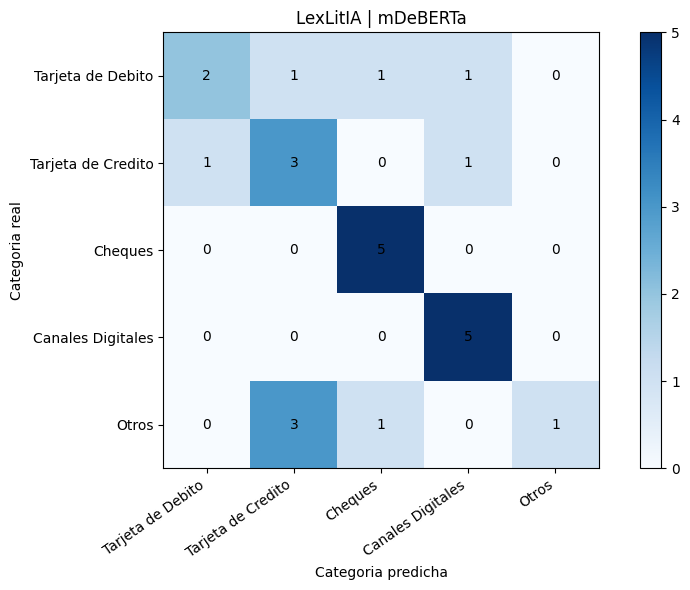

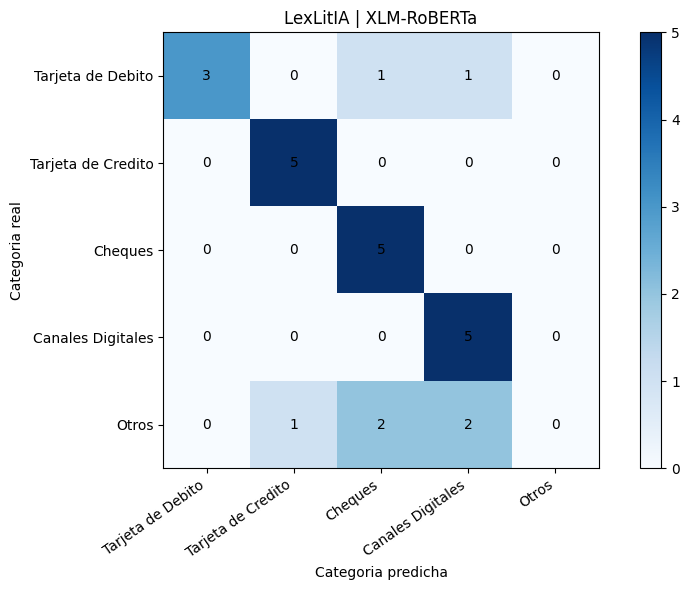

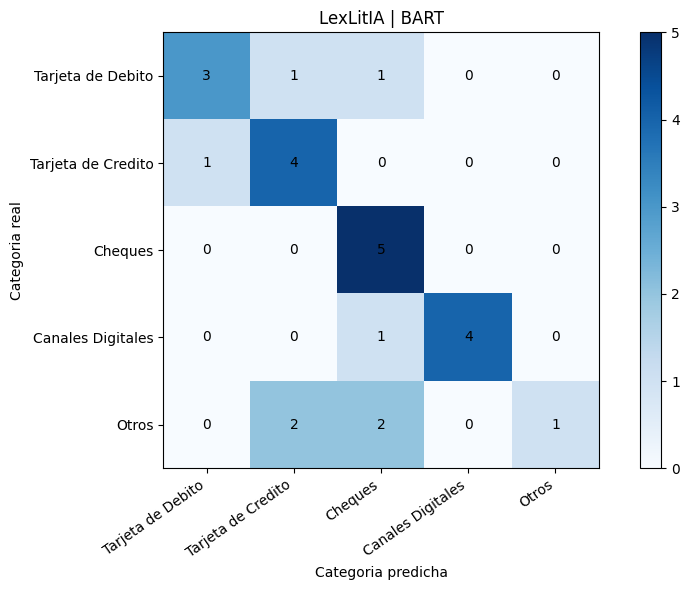

,Modelo,Categoria,Precision,Recall,F1,Soporte
0,mDeBERTa,Tarjeta de Debito,0.6667,0.4,0.5000,5.0
1,mDeBERTa,Tarjeta de Credito,0.4286,0.6,0.5000,5.0
2,mDeBERTa,Cheques,0.7143,1.0,0.8333,5.0
3,mDeBERTa,Canales Digitales,0.7143,1.0,0.8333,5.0
4,mDeBERTa,Otros,1.0000,0.2,0.3333,5.0
5,XLM-RoBERTa,Tarjeta de Debito,1.0000,0.6,0.7500,5.0
6,XLM-RoBERTa,Tarjeta de Credito,0.8333,1.0,0.9091,5.0
7,XLM-RoBERTa,Cheques,0.6250,1.0,0.7692,5.0
8,XLM-RoBERTa,Canales Digitales,0.6250,1.0,0.7692,5.0
9,XLM-RoBERTa,Otros,0.0000,0.0,0.0000,5.0


Errores comunes: ['OTR-EVA-01', 'OTR-EVA-02', 'OTR-EVA-05', 'TDD-EVA-02', 'TDD-EVA-04']
Conclusion: errores documentados.


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, classification_report
)

filas_categoria = []
filas_errores = []

for nombre in MODELOS:

    datos = df_predicciones[
        df_predicciones.modelo == nombre
    ]

    matriz = confusion_matrix(
        datos.categoria_real,
        datos.categoria_predicha,
        labels=NOMBRES
    )

    reporte = classification_report(
        datos.categoria_real,
        datos.categoria_predicha,
        labels=NOMBRES,
        output_dict=True,
        zero_division=0
    )

    for categoria in NOMBRES:
        r = reporte[categoria]
        filas_categoria.append({
            "Modelo": nombre,
            "Categoria": categoria,
            "Precision": r["precision"],
            "Recall": r["recall"],
            "F1": r["f1-score"],
            "Soporte": r["support"]
        })

    for _, fila in datos[~datos.acierto].iterrows():
        filas_errores.append({
            "Modelo": nombre,
            "Familia": fila.familia_id,
            "Categoria real": fila.categoria_real,
            "Prediccion": fila.categoria_predicha
        })

    fig, ax = plt.subplots(figsize=(9, 6))
    im = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=5)

    ax.set_xticks(range(5), NOMBRES, rotation=35, ha="right")
    ax.set_yticks(range(5), NOMBRES)
    ax.set_xlabel("Categoria predicha")
    ax.set_ylabel("Categoria real")
    ax.set_title("LexLitIA | " + nombre)

    for i in range(5):
        for j in range(5):
            ax.text(j, i, str(matriz[i, j]),
                    ha="center", va="center")

    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(
        FIGURAS / f"matriz_{nombre.replace('-', '_')}.png",
        dpi=180, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

df_categoria = pd.DataFrame(filas_categoria)
df_errores = pd.DataFrame(filas_errores)

df_categoria.to_csv(
    RESULTADOS / "metricas_por_categoria.csv",
    index=False, encoding="utf-8-sig"
)
df_errores.to_csv(
    RESULTADOS / "errores_clasificacion.csv",
    index=False, encoding="utf-8-sig"
)

display(df_categoria.round(4))

aciertos = df_predicciones.pivot(
    index="familia_id", columns="modelo", values="acierto"
)

fallos_comunes = aciertos.index[
    ~aciertos.astype(bool).any(axis=1)
].tolist()

print("Errores comunes:", fallos_comunes)
print("Conclusion: errores documentados.")

## ETAPA 7. Decision multicriterio

**Fase:** Seleccion tecnica

**Objetivo:** Aplicar ponderaciones y umbrales de riesgo.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

,Modelo,Accuracy,F1 macro,Latencia media (s),Recall Otros,Parametros,Puntaje Latencia,Puntaje Parametros,Puntaje sobre 100,Cumple accuracy,Cumple recall Otros,Supera umbrales
0,mDeBERTa,0.64,0.6000,0.1295,0.2,278812163,0.9915,1.0000,61.0721,False,False,False
1,XLM-RoBERTa,0.72,0.6395,0.1284,0.0,560943621,1.0000,0.4970,58.2705,False,False,False
2,BART,0.68,0.6540,0.2113,0.2,407344133,0.6076,0.6845,56.5553,False,False,False


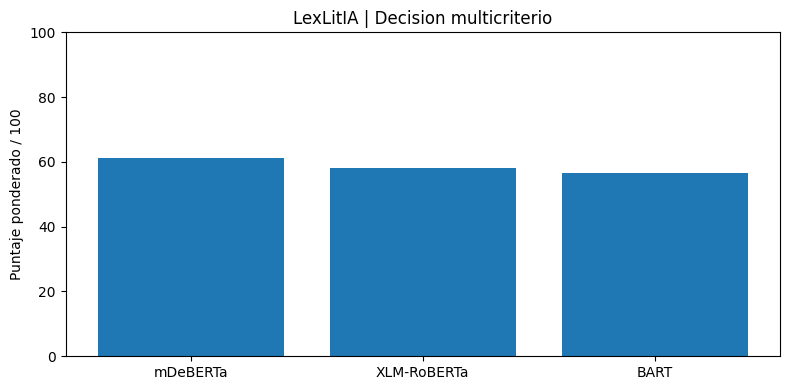

Candidato experimental: mDeBERTa
Modelos que superan umbrales: 0
Conclusion: seleccion condicionada a validacion.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PESOS = {
    "Accuracy": 0.30,
    "F1 macro": 0.30,
    "Recall Otros": 0.20,
    "Latencia": 0.15,
    "Parametros": 0.05
}

assert abs(sum(PESOS.values()) - 1) < 1e-9

parametros = {
    "mDeBERTa": 278812163,
    "XLM-RoBERTa": 560943621,
    "BART": 407344133
}

otros = df_categoria[
    df_categoria.Categoria == "Otros"
][["Modelo", "Recall"]].rename(
    columns={"Recall": "Recall Otros"}
)

decision = df_metricas[
    ["Modelo", "Accuracy", "F1 macro",
     "Latencia media (s)"]
].merge(otros, on="Modelo", validate="one_to_one")

decision["Parametros"] = decision.Modelo.map(parametros)

decision["Puntaje Latencia"] = (
    decision["Latencia media (s)"].min()
    / decision["Latencia media (s)"]
)

decision["Puntaje Parametros"] = (
    decision.Parametros.min() / decision.Parametros
)

decision["Puntaje sobre 100"] = 100 * (
    decision.Accuracy * PESOS["Accuracy"]
    + decision["F1 macro"] * PESOS["F1 macro"]
    + decision["Recall Otros"] * PESOS["Recall Otros"]
    + decision["Puntaje Latencia"] * PESOS["Latencia"]
    + decision["Puntaje Parametros"] * PESOS["Parametros"]
)

decision["Cumple accuracy"] = decision.Accuracy >= 0.80
decision["Cumple recall Otros"] = (
    decision["Recall Otros"] >= 0.60
)
decision["Supera umbrales"] = (
    decision["Cumple accuracy"]
    & decision["Cumple recall Otros"]
)

decision = decision.sort_values(
    "Puntaje sobre 100", ascending=False
).reset_index(drop=True)

display(decision.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(decision.Modelo, decision["Puntaje sobre 100"])
ax.set_ylim(0, 100)
ax.set_ylabel("Puntaje ponderado / 100")
ax.set_title("LexLitIA | Decision multicriterio")
fig.tight_layout()
fig.savefig(
    FIGURAS / "matriz_decision_modelos.png",
    dpi=180, bbox_inches="tight"
)
plt.show()
plt.close(fig)

decision.to_csv(
    RESULTADOS / "matriz_decision.csv",
    index=False, encoding="utf-8-sig"
)

print("Candidato experimental:", decision.iloc[0].Modelo)
print("Modelos que superan umbrales:",
      int(decision["Supera umbrales"].sum()))
print("Conclusion: seleccion condicionada a validacion.")

## ETAPA 8. Exportacion y cierre

**Fase:** Documentacion y reproducibilidad

**Objetivo:** Verificar resultados y preparar las evidencias.

Ejecutar la celda siguiente y verificar sus resultados antes de continuar.

In [8]:
import json
import hashlib
from pathlib import Path

archivos = [
    DATOS / "lexlitia_dataset.csv",
    RESULTADOS / "metricas_comparativas.csv",
    RESULTADOS / "predicciones_detalladas.csv",
    RESULTADOS / "metricas_por_categoria.csv",
    RESULTADOS / "errores_clasificacion.csv",
    RESULTADOS / "matriz_decision.csv"
]

assert all(r.exists() for r in archivos)

manifiesto = []

for ruta in archivos:
    manifiesto.append({
        "archivo": str(ruta.relative_to(RAIZ)),
        "sha256": hashlib.sha256(
            ruta.read_bytes()
        ).hexdigest()
    })

(RAIZ / "docs").mkdir(exist_ok=True)

(RAIZ / "docs" / "manifiesto_ejecucion.json").write_text(
    json.dumps(manifiesto, indent=2),
    encoding="utf-8"
)

print("LEXLITIA | RESUMEN FINAL")
display(df_metricas.round(4))

print("\nCandidato multicriterio:",
      decision.iloc[0]["Modelo"])

print("Superan umbrales:",
      int(decision["Supera umbrales"].sum()))

print("\nLIMITACIONES:")
print("- Dataset sintetico de 50 extractos.")
print("- Evaluacion sobre 25 casos.")
print("- Cinco casos por categoria.")
print("- No acredita desempeno productivo.")
print("- Requiere revision juridica humana.")

print("\nArchivos verificados:", len(archivos))
print("Conclusion: experimento documentado.")

LEXLITIA | RESUMEN FINAL


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Latencia media (s),Latencia mediana (s),Tiempo carga (s),Aciertos
0,mDeBERTa,0.64,0.7048,0.64,0.6000,0.1295,0.1276,12.0886,16
1,XLM-RoBERTa,0.72,0.6167,0.72,0.6395,0.1284,0.1281,31.1499,18
2,BART,0.68,0.7754,0.68,0.6540,0.2113,0.2109,27.9447,17



Candidato multicriterio: mDeBERTa
Superan umbrales: 0

LIMITACIONES:
- Dataset sintetico de 50 extractos.
- Evaluacion sobre 25 casos.
- Cinco casos por categoria.
- No acredita desempeno productivo.
- Requiere revision juridica humana.

Archivos verificados: 6
Conclusion: experimento documentado.
